In this assignment i am using the German data to test whether two fairness interventions reduce differences between groups while preserving predictive performance.

The dataset has 1,000 rows and 21 features

**Import libraries and load the data**

In [1]:
import io, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

url = 'https://archive.ics.uci.edu/static/public/144/statlog+german+credit+data.zip'
# Use an uploaded german.data file if available; otherwise download from UCI.
if Path('german.data').exists():
    raw = Path('german.data').read_bytes()
else:
    with urllib.request.urlopen(url, timeout=60) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    filename = next(n for n in archive.namelist() if n.split('/')[-1] == 'german.data')
    raw = archive.read(filename)
columns = ['checking_status','duration','credit_history','purpose','credit_amount',
           'savings','employment','installment_rate','personal_status_sex',
           'other_debtors','residence_since','property','age','other_installment_plans',
           'housing','existing_credits','job','dependents','telephone','foreign_worker','credit']
df = pd.read_csv(io.BytesIO(raw), sep=r'\s+', header=None, names=columns, na_values=['?'])
assert df.shape == (1000, 21)
assert set(df['credit']) == {1, 2}
y = (df['credit'] == 1).astype(int)
print('Shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Good/bad counts:', y.value_counts().to_dict())

Shape: (1000, 21)
Missing values: 0
Good/bad counts: {1: 700, 0: 300}


**Identify at least two protected attributes in the dataset. Discuss why you chose these attributes.**

I will used the following protected attributes:
Age: Because age can influence access to credit. I will compare under 25 with greater than or equal to 25.
Foreign-worker status: where i will compare recorded foreign workers with non-foreign workers. It may capture unequal treatment associated with migration or employment status.

In [2]:
assert df['age'].notna().all() and df['foreign_worker'].notna().all()
assert set(df['foreign_worker']) <= {'A201', 'A202'}
protected = pd.DataFrame({
    'Age': np.where(df['age'] < 25, 'Under 25', '25 and older'),
    'Foreign-worker status': df['foreign_worker'].map({'A201':'Foreign worker','A202':'Non-foreign worker'})
})
joint = protected['Age'] + ' | ' + protected['Foreign-worker status']
strata = joint + ' | y=' + y.astype(str)
print('Joint group/label counts:'); print(strata.value_counts().to_string())
assert strata.value_counts().min() >= 2, 'Use a different split strategy if a stratum is too small.'
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=42, stratify=strata)
X = df.drop(columns=['credit','age','foreign_worker','personal_status_sex'])
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
S_train, S_test = protected.loc[train_idx], protected.loc[test_idx]
num = X.select_dtypes(include='number').columns.tolist()
cat = X.select_dtypes(exclude='number').columns.tolist()

# sparse_output is used by scikit-learn >= 1.2; fallback supports older installations.
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
preprocess = ColumnTransformer([
    ('numeric', Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]), num),
    ('categorical', Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',encoder)]), cat)
])
Z_train = preprocess.fit_transform(X_train)
Z_test = preprocess.transform(X_test)
print('Training records:', len(train_idx), '| Test records:', len(test_idx))
print('Test group counts:'); print(S_test.apply(pd.Series.value_counts).fillna(0).to_string())

Joint group/label counts:
25 and older | Foreign worker | y=1        582
25 and older | Foreign worker | y=0        235
Under 25 | Foreign worker | y=1             85
Under 25 | Foreign worker | y=0             61
25 and older | Non-foreign worker | y=1     30
25 and older | Non-foreign worker | y=0      4
Under 25 | Non-foreign worker | y=1          3
Training records: 800 | Test records: 200
Test group counts:
                      Age  Foreign-worker status
25 and older        170.0                    0.0
Foreign worker        0.0                  192.0
Non-foreign worker    0.0                    8.0
Under 25             30.0                    0.0


**Train a baseline logistic regression model and evaluate its performance in terms of accuracy and fairness using appropriate metrics.**

In [3]:
def new_model():
    return LogisticRegression(max_iter=2000, solver='lbfgs', C=1.0, random_state=42)
baseline = new_model().fit(Z_train, y_train)
predictions = {'Baseline': baseline.predict(Z_test)}

def safe_rate(numerator, denominator):
    return numerator / denominator if denominator else np.nan

def evaluate(predictions):
    performance, groups, fairness = [], [], []
    truth = y_test.to_numpy()
    for name, pred in predictions.items():
        performance.append({'Model':name, 'Accuracy':accuracy_score(truth,pred),
                            'Balanced accuracy':balanced_accuracy_score(truth,pred),
                            'Macro F1':f1_score(truth,pred,average='macro',zero_division=0)})
        for attribute in S_test.columns:
            rows = []
            for group in sorted(S_test[attribute].unique()):
                mask = S_test[attribute].eq(group).to_numpy()
                t, p = truth[mask], pred[mask]
                row = {'Model':name,'Attribute':attribute,'Group':group,'N':int(mask.sum()),
                       'Actual good':int((t==1).sum()),'Actual bad':int((t==0).sum()),
                       'Selection rate':float((p==1).mean()),
                       'TPR':safe_rate(((p==1)&(t==1)).sum(),(t==1).sum()),
                       'FPR':safe_rate(((p==1)&(t==0)).sum(),(t==0).sum())}
                groups.append(row); rows.append(row)
            r = pd.DataFrame(rows)
            def gap(col):
                return r[col].max()-r[col].min() if r[col].notna().all() else np.nan
            dp, eo, fp = gap('Selection rate'), gap('TPR'), gap('FPR')
            fairness.append({'Model':name,'Attribute':attribute,'DP gap':dp,
                             'Selection-rate ratio':safe_rate(r['Selection rate'].min(),r['Selection rate'].max()),
                             'EO gap':eo,'Equalized odds gap':max(eo,fp) if np.isfinite([eo,fp]).all() else np.nan})
    return pd.DataFrame(performance), pd.DataFrame(groups), pd.DataFrame(fairness)
performance, group_results, fairness = evaluate(predictions)
print(performance.round(4).to_string(index=False))
print(fairness.round(4).to_string(index=False))

   Model  Accuracy  Balanced accuracy  Macro F1
Baseline      0.79             0.7119    0.7271
   Model             Attribute  DP gap  Selection-rate ratio  EO gap  Equalized odds gap
Baseline                   Age   0.251                0.6930  0.2122              0.2122
Baseline Foreign-worker status   0.099                0.8869  0.0526              0.5254


**Implement at least two different fairness interventions (e.g., reweighting, disparate impact remover). Retrain your models using these interventions.**

In [4]:
#Intervention 1: joint-group reweighting
g_train = joint.loc[train_idx]
p_group = g_train.value_counts(normalize=True)
p_label = y_train.value_counts(normalize=True)
p_joint = pd.crosstab(g_train, y_train) / len(y_train)
weights = np.array([p_group[g] * p_label[label] / p_joint.loc[g,label]
                    for g,label in zip(g_train,y_train)])
assert np.isfinite(weights).all() and (weights > 0).all()
weights = weights / weights.mean()
assert np.isclose(weights.mean(), 1)
print('Empty training group/label cells:', int((p_joint == 0).sum().sum()))
print('Weight range:', weights.min().round(3), 'to', weights.max().round(3))
reweighted = new_model().fit(Z_train,y_train,sample_weight=weights)
predictions['Reweighted'] = reweighted.predict(Z_test)

Empty training group/label cells: 1
Weight range: 0.701 to 2.702


The group combines age and foreign-worker status, so both attributes are addressed jointly. When every group/label combination exists, these weights make the weighted label independent of joint group membership.

In [5]:
#Intervention 2: correlation removal
levels = sorted(joint.unique())
A_train = pd.get_dummies(joint.loc[train_idx]).reindex(columns=levels,fill_value=0).to_numpy(dtype=float)
A_test = pd.get_dummies(joint.loc[test_idx]).reindex(columns=levels,fill_value=0).to_numpy(dtype=float)
A_mean = A_train.mean(axis=0)
centered_train = A_train - A_mean
coefficients = np.linalg.lstsq(centered_train,Z_train,rcond=1e-12)[0]
R_train = Z_train - centered_train @ coefficients
R_test = Z_test - (A_test - A_mean) @ coefficients
assert np.allclose(centered_train.T @ R_train, 0, atol=1e-8)
# Scaling is fitted only on the repaired training features.
repair_scaler = StandardScaler().fit(R_train)
repaired = new_model().fit(repair_scaler.transform(R_train),y_train)
predictions['Correlation removal'] = repaired.predict(repair_scaler.transform(R_test))

**Compare the results of the models trained with interventions against the baseline model**

In [6]:
performance, group_results, fairness = evaluate(predictions)
print('PERFORMANCE'); print(performance.round(4).to_string(index=False))
print('FAIRNESS'); print(fairness.round(4).to_string(index=False))
print('GROUP COUNTS AND RATES'); print(group_results.round(4).to_string(index=False))
for name in ['Reweighted','Correlation removal']:
    delta = performance.set_index('Model').loc[name,'Accuracy'] - performance.set_index('Model').loc['Baseline','Accuracy']
    print(f'\n{name}: accuracy change = {delta*100:+.2f} percentage points.')
    for attr in S_test.columns:
        f = fairness[fairness['Attribute']==attr].set_index('Model')
        for metric in ['DP gap','EO gap','Equalized odds gap']:
            before, after = f.loc['Baseline',metric], f.loc[name,metric]
            direction = 'decreased' if after < before else 'increased' if after > before else 'unchanged'
            print(f'  {attr}, {metric}: {before:.3f} → {after:.3f} ({direction}).')

PERFORMANCE
              Model  Accuracy  Balanced accuracy  Macro F1
           Baseline     0.790             0.7119    0.7271
         Reweighted     0.790             0.7024    0.7200
Correlation removal     0.795             0.7060    0.7248
FAIRNESS
              Model             Attribute  DP gap  Selection-rate ratio  EO gap  Equalized odds gap
           Baseline                   Age  0.2510                0.6930  0.2122              0.2122
           Baseline Foreign-worker status  0.0990                0.8869  0.0526              0.5254
         Reweighted                   Age  0.1961                0.7636  0.1648              0.1648
         Reweighted Foreign-worker status  0.0781                0.9107  0.0677              0.4915
Correlation removal                   Age  0.0451                0.9444  0.1093              0.1875
Correlation removal Foreign-worker status  0.2031                0.7969  0.0752              0.4915
GROUP COUNTS AND RATES
              Model 

Model performance: 
The baseline and reweighted models correctly classified 79% of test records. 
Correlation removal achieved 79.5%, an improvement of only one correct prediction out of 200. 
However, the baseline had the highest balanced accuracy and macro F1, showing slightly better performance when both credit classes receive equal importance.

Reweighting:
This intervention provided a more balanced improvement in fairness across the two attributes. The age selection-rate gap decreased from 25.10 to 19.61 percentage and the foreign-worker gap decreased from 9.90 to 7.81 percentage points. Age equal opportunity and equalized odds also improved. 
However, foreign-worker equal opportunity became slightly worse, and macro F1 declined slightly.

Correlation removal: 
This intervention produced the strongest improvement in age selection-rate parity. The gap decreased from 25.10 to 4.51 percentage. Favorable predictions for borrowers under 25 increased from 56.67% to 76.67%, bringing them closer to older borrowers. 

Group-size limitation: 
There were 192 foreign workers but only eight non-foreign workers in the test set. Only 1 non-foreign worker had an actual bad-credit label. Therefore, the 100% false-positive rate for that group reflects just one incorrectly classified person, making the foreign-worker fairness results unstable.


**Visualize the results **

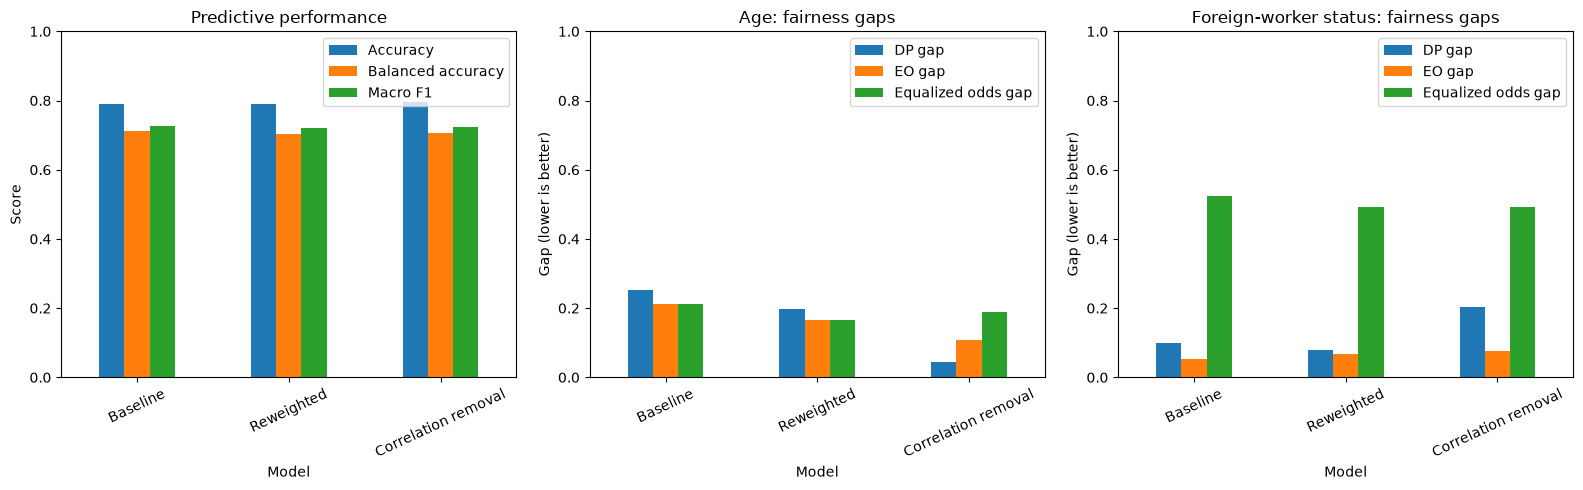

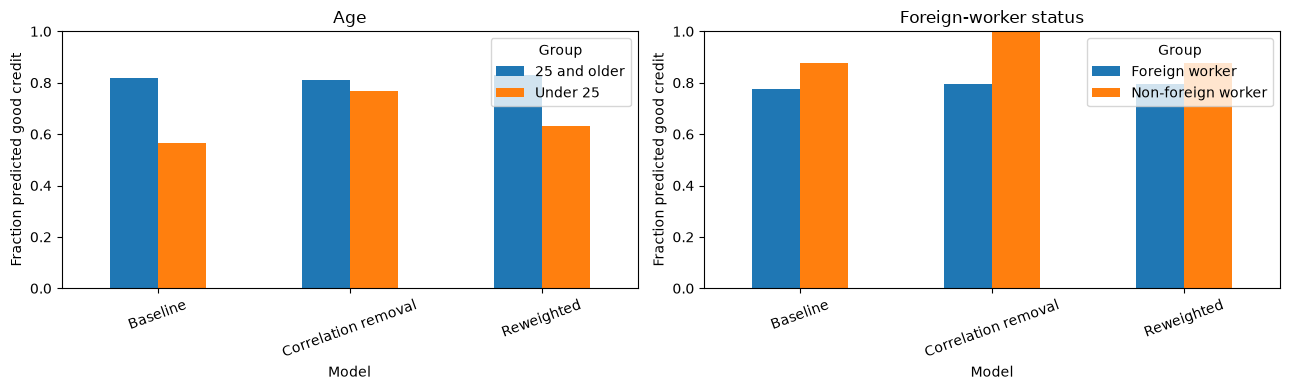

In [7]:
plt.rcParams.update({'font.size':10})
fig, axes = plt.subplots(1,3,figsize=(16,5))
performance.set_index('Model')[['Accuracy','Balanced accuracy','Macro F1']].plot.bar(ax=axes[0],ylim=(0,1),rot=25)
axes[0].set_title('Predictive performance'); axes[0].set_ylabel('Score')
for ax, attr in zip(axes[1:],S_test.columns):
    fairness[fairness['Attribute']==attr].set_index('Model')[['DP gap','EO gap','Equalized odds gap']].plot.bar(ax=ax,ylim=(0,1),rot=25)
    ax.set_title(attr + ': fairness gaps'); ax.set_ylabel('Gap (lower is better)')
fig.tight_layout()
fig, axes = plt.subplots(1,2,figsize=(13,4))
for ax, attr in zip(axes,S_test.columns):
    group_results[group_results['Attribute']==attr].pivot(index='Model',columns='Group',values='Selection rate').plot.bar(ax=ax,ylim=(0,1),rot=20)
    ax.set_title(attr); ax.set_ylabel('Fraction predicted good credit')
fig.tight_layout()

Performance bars with a higher amount is better. 
Fairness-gap bars with a lower figure is better. Selection-rate plots show which groups receive more favorable predictions.